**TD 1 - Smart Machining - Exercise 1**

This exercise will allow you to predict cutting forces and cutting power in external cylindrical turning.

In [1]:
import numpy as np

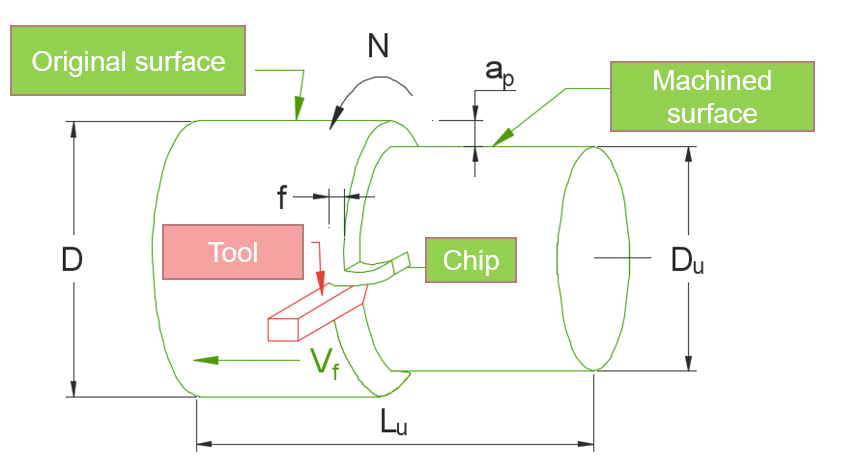

1) The **input parameters** for the turning processes are :


*   Initial Diameter is 1 inch - Calculate in mm (<mark style="background-color: #b6fcb6;">Conversion:</mark> $\mathrm{mm} = 25.4 \cdot \mathrm{inch}$)
*   Final Diameter is 23 mm
*   The maximum depth of cut ($a_p$) is 1 mm
*   The feed per revolution $f_z$ is 0,1 mm/rev and the position angle $κ_r=30^o$
*   The cutting speed for Aluminum is $V_c=$ 200 m/min - (remember to calculate in seconds for the Power !)
*   The estimated specific cutting force for this tool and material is 2000 MPa





In [2]:
Di=1*25.5   #(mm)
Df=23   #(mm)
ap=(Di-Df)/2 # is it more than the maximum depth of cut ?

In [3]:
print("Depth of cut (mm): ",ap)

Depth of cut (mm):  1.25


2) Calculate the depth of cut (mm), the spindle speed (in rpm), the feed velocity (mm/min)

**Solution:**

* Spindle speed: $N (\mathrm{rpm}) = \frac{V_c}{\pi \, D_i}$
* Feed velocity: $V_f (\mathrm{mm/min}) = f_z \cdot n_{tooth} \cdot N$

In [4]:
Vc = 200 * (10**3)  #(mm/min)
N = Vc/(np.pi*Di)   #(rpm)
print("Spindle speed (rpm): ", round(N, 2))

fz = 0.1    #(mm/rev)
Vf = fz*N   #(mm/min)
print("Feed velocity (mm/min): ", round(Vf,2))

Spindle speed (rpm):  2496.55
Feed velocity (mm/min):  249.65


3) Calculate the area of cut when the tool is in contact to the workpiece and the cutting force

**Solution:**

* Area of cut: $A_c = a_p f_t$
* Cutting force: $F_c = K_c a_p f_t$

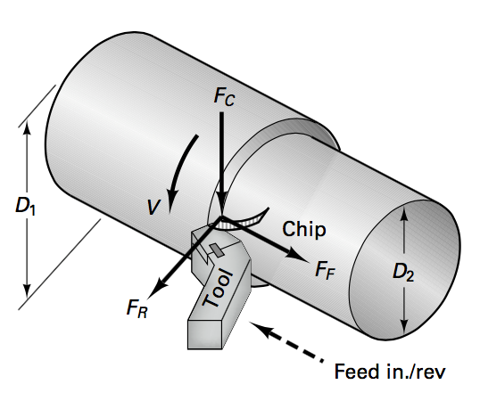

In [5]:
Ac = ap*fz  #(mm2/rev)
print("Area of cut (mm2/rev): ", round(Ac,2))

Kc = 2000   #(MPa)
Fc = Kc*Ac  #(N = N/mm2 * mm2)
print("Cutting force (N): ", round(Fc,2))

Area of cut (mm2/rev):  0.12
Cutting force (N):  250.0


4) The lenght of cut on the bar is 100 mm, calculate the machining time for one pass and the volume for one pass

**Solution:**

* Cutting time: $t_u (\mathrm{min})= \frac{L_u}{V_f}$
* Chip removed volume: $V_u (\mathrm{mm}^3) = a_p \pi D_i L_u$

In [6]:
Lu = 100    #(mm)
tu = Lu/Vf  #(min)
print("Cutting time (min): ", round(tu,2))

Vol_u = ap*np.pi*Di*Lu #(mm3)
print("Chip removed volume (mm3): ", round(Vol_u,2))

Cutting time (min):  0.4
Chip removed volume (mm3):  10013.83


5) Plot a curve of the cutting force (tangential) for the complete time of cut considering that the tool begin from 250 mm distance to the workpiece and the tool velocity when it is not cutting is 500 mm/min. Remember to predict for all passes

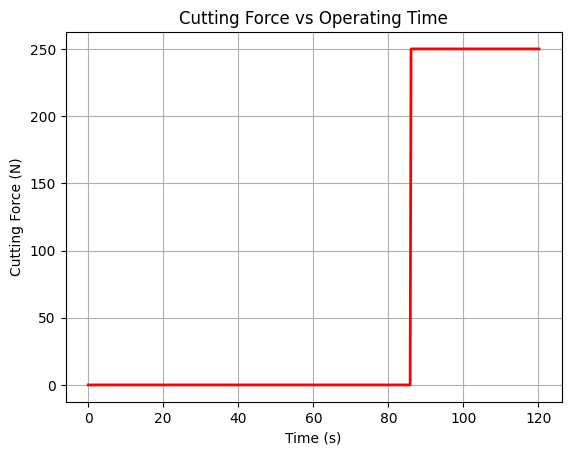

In [7]:
import matplotlib.pyplot as plt

# Complete time
tm = 120    #(min)
# Lengths
L1 = 250    #(mm)
dl = 1  #(mm) -> spatial step
dt = dl/Vf * 60  #(s) -> temporal step: required step in order to move of dl=1mm

# Number of elements
N = round(tm/dt) + 1

time = np.arange(0, tm + dt, dt)
length = np.arange(0, L1+Lu, (L1+Lu)/N)
force = np.where(length > L1, Fc, 0)

M = np.column_stack((time, length, force))

plt.plot(M[:,0], M[:,2], color="red", linewidth=2)
plt.xlabel("Time (s)")
plt.ylabel("Cutting Force (N)")
plt.grid(True)
plt.title("Cutting Force vs Operating Time")
plt.show()

6) Now calculate the same in cutting power.

**Solution:** considering the given parameters, the total power $P_u \approx P_c = F_c V_c$ (miss $K_f$ in order to calculate $P_f$)

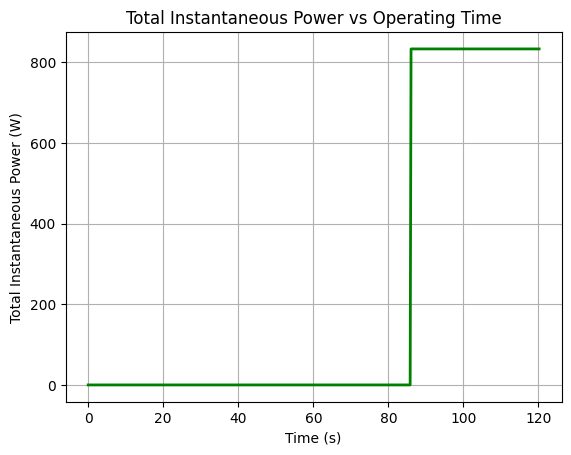

In [9]:
Vc = Vc * (10**(-3)/60)  #(mm/min -> m/s)
Pc = force * Vc # where's no material => Fc = 0

M = np.column_stack((M, Pc))

plt.plot(M[:,0], M[:,3], color="green", linewidth=2)
plt.xlabel("Time (s)")
plt.ylabel("Total Instantaneous Power (W)")
plt.grid(True)
plt.title("Total Instantaneous Power vs Operating Time")
plt.show()